# Egyptian Pharmaceutical Dataset - Initial Exploratory Data Analysis (EDA)

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [41]:

Dataframe = pd.read_csv('../data/eg_drugs.csv')
print("data amount", Dataframe.shape)

Dataframe.info()


data amount (26562, 25)
<class 'pandas.DataFrame'>
RangeIndex: 26562 entries, 0 to 26561
Data columns (total 25 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           26562 non-null  int64  
 1   name                         26562 non-null  str    
 2   arabic                       26562 non-null  str    
 3   active                       23805 non-null  str    
 4   company                      26252 non-null  str    
 5   price                        26557 non-null  str    
 6   oldprice                     11362 non-null  str    
 7   availability                 26219 non-null  float64
 8   barcode                      10532 non-null  str    
 9   slug                         26561 non-null  str    
 10  units                        26562 non-null  int64  
 11  description                  25427 non-null  str    
 12  uses                         8107 non-null   str    
 13  mat

In [42]:
duplicate_rows = Dataframe.duplicated().sum()
print("duplicate rows:", duplicate_rows)

id_duplicates = Dataframe['id'].duplicated().sum()
print("duplicate IDs :", id_duplicates)

Dataframe.head()

duplicate rows: 0
duplicate IDs : 0


,id,name,arabic,active,company,price,oldprice,availability,barcode,slug,...,uses_summary_en,warning_high_blood_pressure,warning_diabetes,warning_pregnancy,warning_lactation,warning_kidney,warning_liver,warning_heart,warnings_summary,warnings_summary_en
0,1,1 2 3 (one two three) syrup 120 ml,ون تو ثري شراب 120 مل,Chlorpheniramine+paracetamol+pseudoephedrine,Hikma,40.00.,32.00.,NaN,6221000000010,1,...,temporarily relieves nasal congestion due to t...,1,1,1,1,0,0,1,يحذر أو يوصى بالحذر تحت إشراف طبي في الحالات ا...,Caution or warning advised under medical super...
1,2,1 2 3 (one two three) 20 f.c.tabs,ون تو ثري 20 قرص,Chlorpheniramine+paracetamol+pseudoephedrine,Hikma,40.00.,24.00.,NaN,6221000000010,2,...,temporarily relieves nasal congestion due to t...,1,1,1,1,0,0,1,يحذر أو يوصى بالحذر تحت إشراف طبي في الحالات ا...,Caution or warning advised under medical super...
2,3,5-fluorouracil-ebewe 250mg/5ml i.v. vial,فلورويوراسيل 250مجم/5مل فيال وريد,Fluorouracil,Shanghai xudong haipu pharmaceutical > acdima ...,74.00.,50.00.,NaN,9088881320685,3,...,Fluorouracil Cream is recommended for the topi...,0,0,1,0,0,0,0,يحذر أو يوصى بالحذر تحت إشراف طبي في الحالات ا...,Caution or warning advised under medical super...
3,4,mooagar sachets,مو اجار 2جم اكياس,agar,hexa pharma company,75,NaN,3710.0,NaN,mooagar-sachets,...,No registered indications.,0,0,0,0,0,0,0,لا توجد تحذيرات خاصة مسجلة لهذه الحالات. استشر...,No special warnings registered for these condi...
4,5,limitless lactoferrin 100 mg 30 sachets,ليمتلس لاكتوفيرين 100 مجم 30 كيس,lactoferrin,eva pharma,485,385,3711.0,NaN,limitless-lactoferrin-100-mg-30-sachets,...,No registered indications.,0,0,0,0,0,0,0,لا توجد تحذيرات خاصة مسجلة لهذه الحالات. استشر...,No special warnings registered for these condi...


In [43]:
missing_count = Dataframe.isnull().sum()


missing_percent = (missing_count / len(Dataframe)) * 100

missing_table = pd.DataFrame({
    'missing numbers': missing_count,
    'missing percentage %': missing_percent.round(2)
})

missing_table[missing_table['missing numbers'] > 0].sort_values(by='missing numbers', ascending=False)

,missing numbers,missing percentage %
uses,18455,69.48
barcode,16030,60.35
oldprice,15200,57.22
matched_fda_ingredients,6980,26.28
active,2757,10.38
description,1135,4.27
availability,343,1.29
company,310,1.17
price,5,0.02
slug,1,0.00


In [44]:
has_dot = Dataframe['price'].str.endswith('.', na=False)

print("Values with a dot:", has_dot.sum())

Values with a dot: 339


In [45]:
Dataframe.describe()


,id,availability,units,warning_high_blood_pressure,warning_diabetes,warning_pregnancy,warning_lactation,warning_kidney,warning_liver,warning_heart
count,26562.000000,26219.000000,26562.000000,26562.000000,26562.000000,26562.000000,26562.000000,26562.000000,26562.000000,26562.000000
mean,17276.624915,4.005035,1.864167,0.121075,0.117950,0.265831,0.164784,0.234470,0.153302,0.199458
std,10150.040713,61.688500,4.609505,0.326221,0.322556,0.441783,0.370993,0.423675,0.360285,0.399600
min,1.000000,-3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7746.250000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,17959.500000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,26125.250000,1.000000,2.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,33940.000000,3837.000000,500.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [46]:
Dataframe.nunique()

id                             26562
name                           26557
arabic                         26403
active                          9102
company                         5533
price                           2319
oldprice                        1383
availability                     208
barcode                        10139
slug                           26560
units                             25
description                     2909
uses                            5111
matched_fda_ingredients         5887
uses_summary                    6784
uses_summary_en                 2640
warning_high_blood_pressure        2
warning_diabetes                   2
warning_pregnancy                  2
warning_lactation                  2
warning_kidney                     2
warning_liver                      2
warning_heart                      2
warnings_summary                  90
warnings_summary_en               90
dtype: int64

# 2. Intial data cleaning

In [47]:
Dataframe = Dataframe[Dataframe['name']!= "دليل دواء مصر"]

print("rows after drop:", Dataframe.shape)

rows after drop: (26558, 25)


In [48]:
Dataframe["price"] = Dataframe["price"].astype(str).str.strip('.')

Dataframe["oldprice"] = Dataframe["oldprice"].astype(str).str.strip('.')


Dataframe['price'] = pd.to_numeric(Dataframe['price'], errors='coerce')

Dataframe['oldprice'] = pd.to_numeric(Dataframe['oldprice'], errors='coerce')



print(Dataframe[['price', 'oldprice']].dtypes)


Dataframe.info()

price       float64
oldprice    float64
dtype: object
<class 'pandas.DataFrame'>
Index: 26558 entries, 0 to 26561
Data columns (total 25 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           26558 non-null  int64  
 1   name                         26558 non-null  str    
 2   arabic                       26558 non-null  str    
 3   active                       23805 non-null  str    
 4   company                      26252 non-null  str    
 5   price                        26557 non-null  float64
 6   oldprice                     11362 non-null  float64
 7   availability                 26219 non-null  float64
 8   barcode                      10532 non-null  str    
 9   slug                         26557 non-null  str    
 10  units                        26558 non-null  int64  
 11  description                  25427 non-null  str    
 12  uses                         8107 no

In [49]:
Dataframe.loc[Dataframe['availability'] < 0, 'availability'] = 0

illogical_availability = (Dataframe['availability'] < 0).sum()
print("illogical availability values:", illogical_availability)
                                   

illogical availability values: 0


In [50]:
Dataframe['name'] = Dataframe['name'].str.strip()

Dataframe['company'] = Dataframe['company'].str.strip()



In [51]:
string_columns = Dataframe.select_dtypes(include=['object', 'string']).columns

for col in string_columns:
    Dataframe[col] = Dataframe[col].str.strip()

In [52]:
Dataframe.loc[Dataframe['company'].str.lower() == 'company', 'company'] = None
not_real_companies = (Dataframe['company'].str.lower() == 'company').sum()
print("Not real companies:", not_real_companies)


Not real companies: 0


# 3. Feature Engineering

In [66]:
Dataframe['price_diff'] = Dataframe['price'] - Dataframe['oldprice']

Dataframe['price_change_percent'] = (
    (Dataframe['price_diff'] / Dataframe['oldprice']) * 100
).round(2)

Dataframe['is_available'] = (Dataframe['availability'] > 0).astype(int)
Dataframe[['name', 'price', 'oldprice', 'price_diff', 'price_change_percent', 'is_available']].head()

,name,price,oldprice,price_diff,price_change_percent,is_available
0,1 2 3 (one two three) syrup 120 ml,40.0,32.0,8.0,25.00,0
1,1 2 3 (one two three) 20 f.c.tabs,40.0,24.0,16.0,66.67,0
2,5-fluorouracil-ebewe 250mg/5ml i.v. vial,74.0,50.0,24.0,48.00,0
3,mooagar sachets,75.0,NaN,NaN,NaN,1
4,limitless lactoferrin 100 mg 30 sachets,485.0,385.0,100.0,25.97,1


In [65]:
avg_price_change = Dataframe['price_change_percent'].mean().round(2)

max_price_change = Dataframe['price_change_percent'].max()
min_price_change = Dataframe['price_change_percent'].min()

availability_rate = (Dataframe['is_available'].mean() * 100).round(2)

print(f"Average Price Change: {avg_price_change}%")
print(f"Maximum Price Increase: {max_price_change}%")
print(f"Minimum Price Change: {min_price_change}%")
print(f"Overall Market Availability Rate: {availability_rate}%")

Average Price Change: inf%
Maximum Price Increase: inf%
Minimum Price Change: -100.0%
Overall Market Availability Rate: 26.5%


#3.1 minor issue --data cleaning--

In [55]:
Dataframe['price'] = Dataframe['price'].replace(0, np.nan)
Dataframe['oldprice'] = Dataframe['oldprice'].replace(0, np.nan)

avg_price_change = Dataframe['price_change_percent'].mean().round(2)
max_price_change = Dataframe['price_change_percent'].max()


print(f"Average Price Change: {avg_price_change}%")
print(f"Maximum Price Increase: {max_price_change}%")

Average Price Change: inf%
Maximum Price Increase: inf%


In [64]:
Dataframe.sort_values(by='price_change_percent', ascending=False)[
    ['name', 'oldprice', 'price', 'price_diff', 'price_change_percent', 'company']
].head(5)

,name,oldprice,price,price_diff,price_change_percent,company
19307,Proxerex 30 sachet,NaN,1200.0,1200.0,inf,E-pharma > alfasigma
8864,Trixy 5mg 10 tab,NaN,5.0,5.0,inf,Delta pharma
5026,سرنجة اعطاء دواء,NaN,10.0,10.0,inf,NaN
5049,Prombet cream 50 gm,NaN,70.0,70.0,inf,Star pharm
5050,2m whites beegu marin spray,NaN,135.0,135.0,inf,2m whites pharma


In [67]:
print(f"Mean Price Change: {Dataframe['price_change_percent'].mean().round(2)}%")
print(f"Median Price Change: {Dataframe['price_change_percent'].median().round(2)}%")



Mean Price Change: 75.66%
Median Price Change: 40.0%


# 4. Exploratory Data Visualization (Visual EDA)

C:\Users\ou3be\AppData\Local\Temp\ipykernel_22900\3812516003.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  availablity_chart = sns.countplot(x='is_available', data=Dataframe, palette=['#e74c3c', '#2ecc71'])


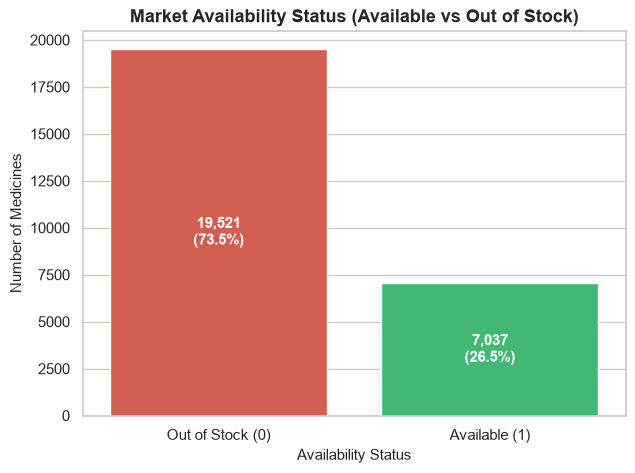

In [58]:
plt.figure(figsize=(7, 5))
sns.set_theme(style="whitegrid")

availablity_chart = sns.countplot(x='is_available', data=Dataframe, palette=['#e74c3c', '#2ecc71'])
plt.title("Market Availability Status (Available vs Out of Stock)", fontsize=13, fontweight='bold')
plt.xlabel("Availability Status", fontsize=11)
plt.ylabel("Number of Medicines", fontsize=11)
plt.xticks(ticks=[0, 1], labels=['Out of Stock (0)', 'Available (1)'])


total = len(Dataframe)
for p in availablity_chart.patches:
    count = int(p.get_height())
    percentage = f"{100 * count / total:.1f}%"
    availablity_chart.annotate(f"{count:,}\n({percentage})", 
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.show()

C:\Users\ou3be\AppData\Local\Temp\ipykernel_22900\1847137017.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


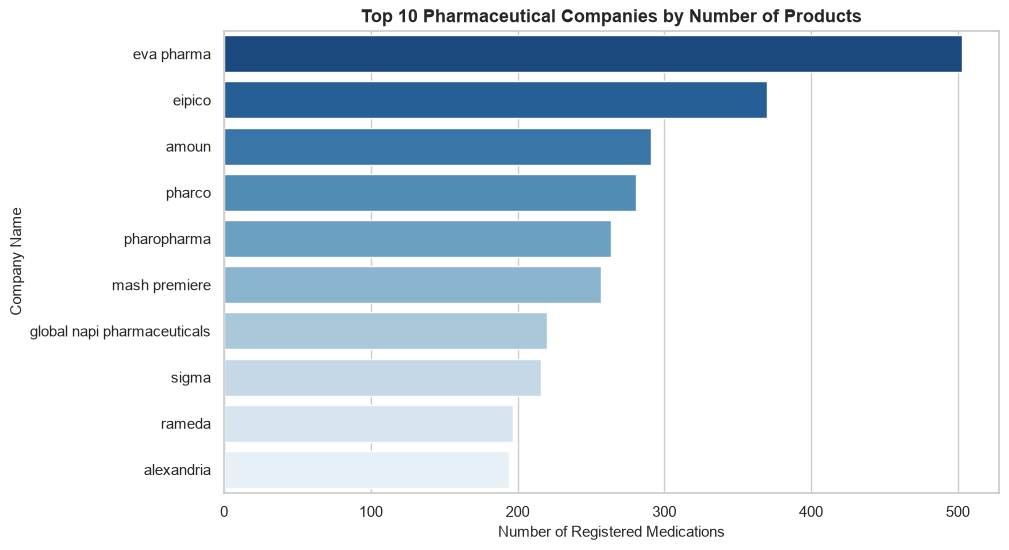

In [59]:
top_companies = Dataframe['company'].value_counts().head(10)
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_companies.values, 
    y=top_companies.index, 
    palette='Blues_r'
)

plt.title("Top 10 Pharmaceutical Companies by Number of Products", fontsize=13, fontweight='bold')
plt.xlabel("Number of Registered Medications", fontsize=11)
plt.ylabel("Company Name", fontsize=11)

plt.show()

In [60]:
top_companies

company
eva pharma                     503
eipico                         370
amoun                          291
pharco                         281
pharopharma                    264
mash premiere                  257
global napi pharmaceuticals    220
sigma                          216
rameda                         197
alexandria                     194
Name: count, dtype: int64

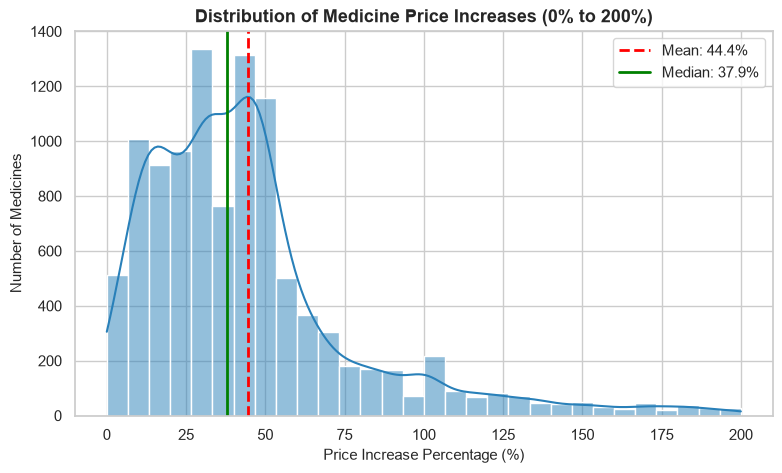

In [61]:
price_changes = Dataframe[
    (Dataframe['price_change_percent'].notna()) & 
    (Dataframe['price_change_percent'] >= 0) & 
    (Dataframe['price_change_percent'] <= 200)
]['price_change_percent']

plt.figure(figsize=(9, 5))

sns.histplot(price_changes, bins=30, kde=True, color='#2980b9')

plt.axvline(price_changes.mean(), color='red', linestyle='--', linewidth=2, label=f"Mean: {price_changes.mean():.1f}%")
plt.axvline(price_changes.median(), color='green', linestyle='-', linewidth=2, label=f"Median: {price_changes.median():.1f}%")

plt.title("Distribution of Medicine Price Increases (0% to 200%)", fontsize=13, fontweight='bold')
plt.xlabel("Price Increase Percentage (%)", fontsize=11)
plt.ylabel("Number of Medicines", fontsize=11)
plt.legend(fontsize=11)

plt.show()

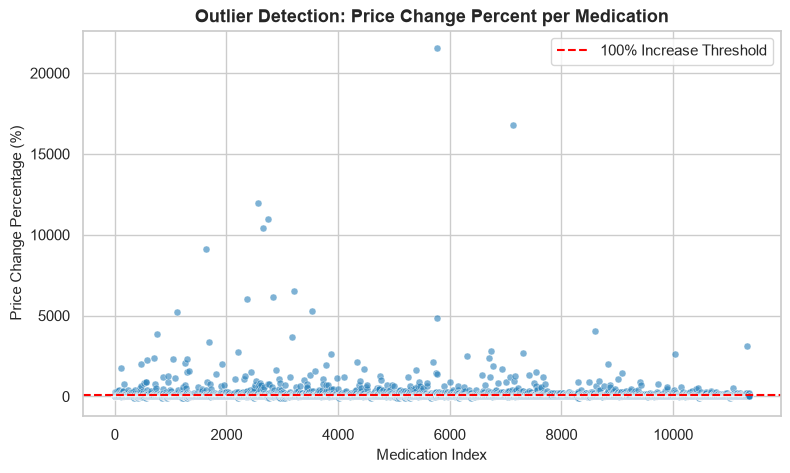

In [62]:
scatter_data = Dataframe[Dataframe['price_change_percent'].notna()]

plt.figure(figsize=(9, 5))

sns.scatterplot(
    x=range(len(scatter_data)), 
    y=scatter_data['price_change_percent'], 
    color='#2980b9', 
    alpha=0.6,          
    s=25                 
)

plt.axhline(100, color='red', linestyle='--', label='100% Increase Threshold')

plt.title("Outlier Detection: Price Change Percent per Medication", fontsize=13, fontweight='bold')
plt.xlabel("Medication Index", fontsize=11)
plt.ylabel("Price Change Percentage (%)", fontsize=11)
plt.legend()

plt.show()

In [63]:
Dataframe.to_csv('../data/eg_drugs_cleaned.csv', index=False)
print("Cleaned dataset saved as 'eg_drugs_cleaned.csv'")

Cleaned dataset saved as 'eg_drugs_cleaned.csv'
